In [1]:
import os
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

h5_path = Path("/content/drive/MyDrive/ncmapss/N-CMAPSS_DS02-006.h5")

if not h5_path.is_file():
    raise FileNotFoundError(f"Dosya bu konumda bulunamadı: {h5_path}")

os.environ["N_CMAPSS_H5"] = str(h5_path)
print("Veri dosyası bulundu:", h5_path)

Mounted at /content/drive
Veri dosyası bulundu: /content/drive/MyDrive/ncmapss/N-CMAPSS_DS02-006.h5


## DS02 XGBoost baseline

Her satır bir uçuşu, hedef ise uçuş sonundaki kalan uçuş sayısını (RUL) temsil eder. Jupyter çekirdeğinde proje bağımlılıklarına ek olarak `xgboost>=2.1` gerekir.


In [2]:
import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from xgboost import XGBRegressor


# Colab'da Drive kullanıyorsanız None yerine kendi .h5 dosyanızın tam yolunu yazın.
# Örnek: "/content/drive/MyDrive/veri/N-CMAPSS_DS02-006.h5"
drive_h5_path = None

if drive_h5_path and not os.environ.get("N_CMAPSS_H5"):
    from google.colab import drive

    drive.mount("/content/drive")
    os.environ["N_CMAPSS_H5"] = drive_h5_path


def resolve_ncmapss_paths(start=None):
    external_path = os.environ.get("N_CMAPSS_H5")
    if external_path:
        h5_path = Path(external_path).expanduser().resolve()
        if not h5_path.is_file():
            raise FileNotFoundError(f"N_CMAPSS_H5 dosyası bulunamadı: {h5_path}")
        return h5_path

    working_directory = Path.cwd().resolve() if start is None else Path(start).resolve()
    for parent in (working_directory, *working_directory.parents):
        project_root = parent if parent.name == "n_cmapss" else parent / "n_cmapss"
        if (project_root / "notebooks").is_dir():
            h5_path = project_root / "data" / "N-CMAPSS_DS02-006.h5"
            if h5_path.is_file():
                return h5_path
            raise FileNotFoundError(
                f"Yerel DS02 dosyası bulunamadı: {h5_path}. "
                "Dosyayı bu konuma koyun veya N_CMAPSS_H5 ile tam yolunu verin."
            )

    raise FileNotFoundError(
        "DS02 dosyasını bulmak için N_CMAPSS_H5 ile tam yolu verin. "
        "Colab'da Drive kullanıyorsanız bu hücrede drive_h5_path değerini ayarlayın."
    )


h5_path = resolve_ncmapss_paths()

# Projenin ortak girdileri ve HDF5 içindeki sütun adı dizileri.
FEATURE_GROUPS = (("W", "W_var"), ("X_s", "X_s_var"))

print(f"Veri dosyası: {h5_path}")


Veri dosyası: /content/drive/MyDrive/ncmapss/N-CMAPSS_DS02-006.h5


## Uçuş özellikleri

Ortak 4 çalışma koşulu ve 14 fiziksel sensör kanalından uçuş ortalaması, standart sapma ve aynı motorun o uçuş dahil birikimli uçuş ortalaması hesaplanır. RUL etiketi HDF5 dosyasındaki Y dizisinden alınır.


In [3]:
def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


def load_flights(split):
    with h5py.File(h5_path, "r") as h5:
        id_names = read_names(h5["A_var"])
        identifiers = h5[f"A_{split}"][:, :2] if id_names[:2] == ["unit", "cycle"] else (
            h5[f"A_{split}"][:, :][:, [id_names.index("unit"), id_names.index("cycle")]]
        )
        identifiers = identifiers.astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5[f"Y_{split}"][starts].reshape(-1)
        flights = pd.DataFrame(identifiers[starts], columns=["unit", "cycle"])
        flights["RUL"] = targets

        feature_blocks = []
        mean_columns = []
        for channel_group, names_key in FEATURE_GROUPS:
            dataset = h5[f"{channel_group}_{split}"]
            names = [f"{channel_group}_{name}" for name in read_names(h5[names_key])]
            flight_means = np.empty((len(starts), len(names)))
            flight_stds = np.empty_like(flight_means)
            for index, (start, end) in enumerate(zip(starts, ends)):
                samples = dataset[start:end]
                flight_means[index] = np.mean(samples, axis=0, dtype=np.float64)
                flight_stds[index] = np.std(samples, axis=0, dtype=np.float64)

            group_means = [f"{name}_mean" for name in names]
            mean_columns.extend(group_means)
            feature_blocks.extend([
                pd.DataFrame(flight_means, columns=group_means),
                pd.DataFrame(flight_stds, columns=[f"{name}_std" for name in names]),
            ])

    flights = pd.concat([flights, *feature_blocks], axis=1, verify_integrity=True)
    if flights.duplicated(["unit", "cycle"]).any():
        raise ValueError(f"{split}: HDF5 içinde kesintili uçuş kaydı bulundu.")
    flights = flights.sort_values(["unit", "cycle"], ignore_index=True)
    history = (
        flights.groupby("unit", sort=False)[mean_columns]
        .expanding()
        .mean()
        .droplevel("unit")
        .add_suffix("_to_date")
    )
    return flights.join(history)


dev = load_flights("dev")
test = load_flights("test")
feature_columns = dev.columns.drop(["unit", "cycle", "RUL"]).tolist()
print(f"Dev: {len(dev)} uçuş | Test: {len(test)} uçuş | Model girdisi: {len(feature_columns)}")


Dev: 446 uçuş | Test: 202 uçuş | Model girdisi: 54


## Motor bazında ayrım


In [4]:
dev_units = sorted(dev["unit"].unique().tolist())
test_units = sorted(test["unit"].unique().tolist())
if len(dev_units) < 2 or set(dev_units) & set(test_units):
    raise ValueError("Dev/test motor ayrımı geçersiz.")

# Projedeki ilk leave-one-engine-out katı.
validation_units = dev_units[:1]
train_units = dev_units[1:]
train = dev.loc[dev["unit"].isin(train_units)]
validation = dev.loc[dev["unit"].isin(validation_units)]

print(f"Eğitim motorları: {train_units}")
print(f"Doğrulama motorları: {validation_units}")
print(f"Resmî test motorları: {test_units}")


Eğitim motorları: [5, 10, 16, 18, 20]
Doğrulama motorları: [2]
Resmî test motorları: [11, 14, 15]


## Erken durdurmalı eğitim


In [5]:
model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
)
model = XGBRegressor(**model_params, n_estimators=1000, early_stopping_rounds=50)
model.fit(
    train[feature_columns],
    train["RUL"],
    eval_set=[(validation[feature_columns], validation["RUL"])],
    verbose=False,
)
best_rounds = model.best_iteration + 1
print(f"Doğrulama RMSE'sine göre seçilen ağaç sayısı: {best_rounds}")


Doğrulama RMSE'sine göre seçilen ağaç sayısı: 148


## Eğitim ve doğrulama hataları


In [6]:
def rul_metrics(actual, predicted):
    errors = np.asarray(predicted) - np.asarray(actual)
    return {
        "MAE (uçuş)": np.abs(errors).mean(),
        "RMSE (uçuş)": np.sqrt(np.square(errors).mean()),
    }


dev_metrics = pd.DataFrame({
    "Eğitim": rul_metrics(train["RUL"], model.predict(train[feature_columns])),
    "Doğrulama": rul_metrics(validation["RUL"], model.predict(validation[feature_columns])),
})
display(dev_metrics.round(2))


,Eğitim,Doğrulama
MAE (uçuş),3.33,5.28
RMSE (uçuş),4.54,7.31


## Nihai model ve test hataları

Doğrulamada seçilen ağaç sayısıyla nihai model tüm dev motorlarında eğitilir ve resmî test motorlarında değerlendirilir.


In [7]:
final_model = XGBRegressor(**model_params, n_estimators=best_rounds)
final_model.fit(dev[feature_columns], dev["RUL"])

test_results = test[["unit", "cycle", "RUL"]].copy()
test_results["RUL_tahmin"] = final_model.predict(test[feature_columns])

test_metrics = {"Tüm test uçuşları": rul_metrics(test_results["RUL"], test_results["RUL_tahmin"])}
for unit, flights in test_results.groupby("unit"):
    test_metrics[f"Motor {unit}"] = rul_metrics(flights["RUL"], flights["RUL_tahmin"])

display(pd.DataFrame.from_dict(test_metrics, orient="index").round(2))


,MAE (uçuş),RMSE (uçuş)
Tüm test uçuşları,24.84,30.58
Motor 11,13.87,16.44
Motor 14,27.14,32.93
Motor 15,31.88,36.76


## Test motorlarının RUL grafikleri


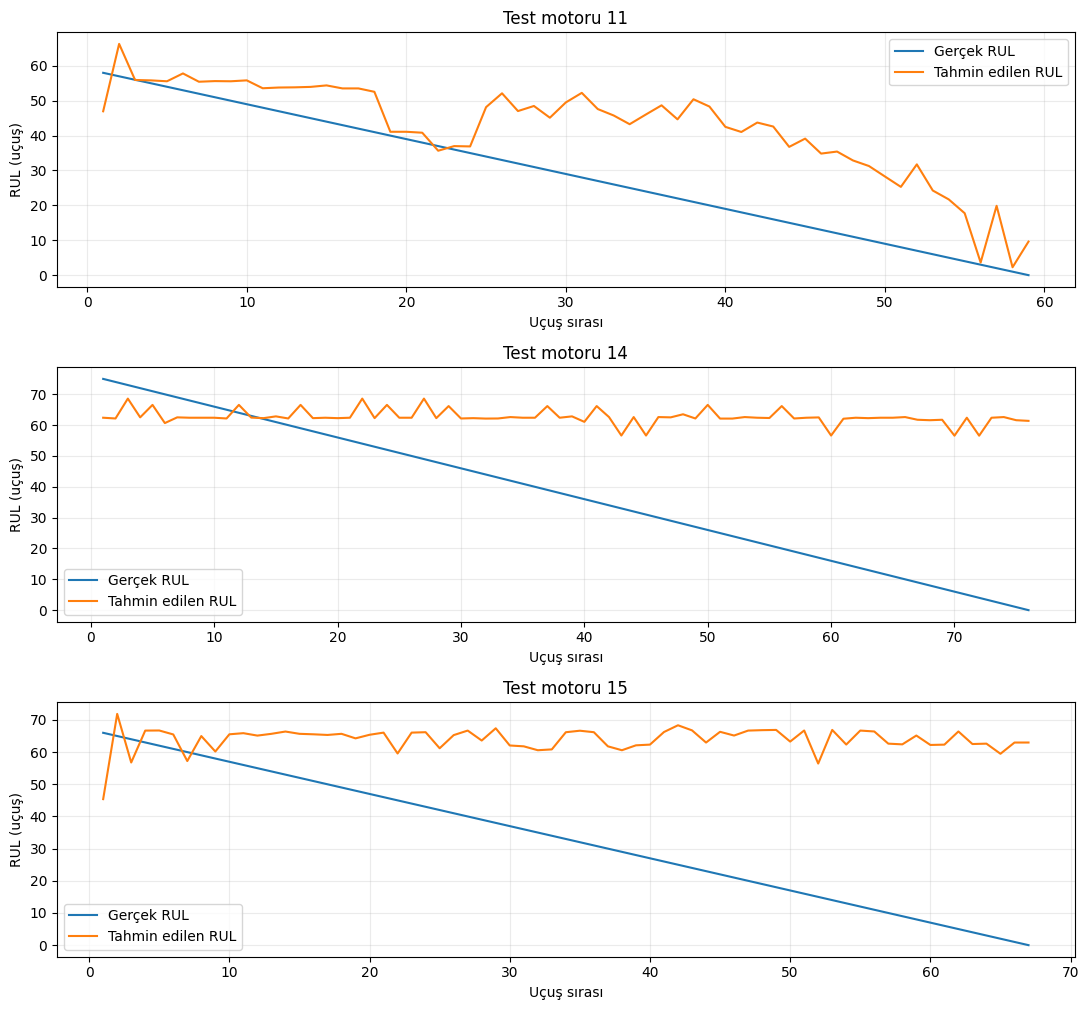

In [8]:
fig, axes = plt.subplots(len(test_units), 1, figsize=(11, 3.4 * len(test_units)), squeeze=False)
for ax, (unit, flights) in zip(axes[:, 0], test_results.groupby("unit")):
    flights = flights.sort_values("cycle")
    ax.plot(flights["cycle"], flights["RUL"], label="Gerçek RUL")
    ax.plot(flights["cycle"], flights["RUL_tahmin"], label="Tahmin edilen RUL")
    ax.set(title=f"Test motoru {unit}", xlabel="Uçuş sırası", ylabel="RUL (uçuş)")
    ax.legend()
    ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()


In [9]:
print(f"Bir uçuş için {len(feature_columns)} girdi var.")
display(dev[feature_columns].iloc[0].rename("İlk uçuşun değeri").to_frame())

Bir uçuş için 54 girdi var.


,İlk uçuşun değeri
W_alt_mean,24387.123597
W_Mach_mean,0.636521
W_TRA_mean,69.647729
W_T2_mean,466.733396
W_alt_std,6930.606188
W_Mach_std,0.075528
W_TRA_std,16.876854
W_T2_std,18.826884
X_s_T24_mean,549.869167
X_s_T30_mean,1301.106726
